# Components of Time Series Decomposition

**Trend** is the long-term direction: going up, going down, or flat. Example: a company’s sales slowly growing over 5 years.

**Seasonality** is a pattern that repeats at a fixed, known interval. Example: ice cream sales peak every summer, and shop sales jump every Sunday or every Diwali.

**Cyclic pattern** is up-and-down waves with no fixed length, such as economic booms and recessions. They’re hard to predict, so beginners mostly treat them as part of the trend.

**Noise** (residual) is the random leftover that no pattern can explain. Every real series has some, and a good model should not try to predict it.

# TYpes of Decomposition

**Additive**: Value = Trend + Seasonality + Noise. Use it when the seasonal ups and downs stay about the same size over time.

**Multiplicative**: Value = Trend × Seasonality × Noise. Use it when the seasonal swings grow bigger as the level grows. 
    This is very common in sales data.


**Frequency** means how often data is recorded  ex- d(day) ,m(month) ,ms(monthly),q(quarterly), h(hourly)

In [40]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

In [41]:
stock_data=yf.download("AAPL",start='2024-01-01', end="2024-12-30")

[*********************100%***********************]  1 of 1 completed


In [42]:
stock_data.head(10)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-01-02,183.404007,186.170285,181.675085,184.895814,82488700
2024-01-03,182.030762,183.641134,181.220631,182.001124,58414500
2024-01-04,179.718933,180.884713,178.701340,179.956033,71983600
2024-01-05,178.997726,180.558698,177.999897,179.797983,62379700
2024-01-08,183.324982,183.364508,179.313886,179.896776,59144500
2024-01-09,182.910019,182.919893,180.529043,181.704712,42841800
2024-01-10,183.947403,184.154865,181.704740,182.129569,46792900
2024-01-11,183.354614,184.797036,181.408341,184.293169,49128400


In [43]:
stock_data.tail(10)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-12-13,246.342270,247.493901,244.465888,246.034506,33155300
2024-12-16,249.231323,249.568885,245.865748,246.203310,51694800
2024-12-17,251.653748,252.001232,247.980408,248.278250,51356400
2024-12-18,246.262878,252.447989,245.955114,250.343268,56774100
2024-12-19,247.990295,250.184379,245.309752,245.716801,60882300
2024-12-20,252.656479,253.162799,243.919877,246.252937,147495300
2024-12-23,253.430847,253.808099,251.623953,252.934450,40858800
2024-12-24,256.339722,256.349629,253.450669,253.649240,23234700


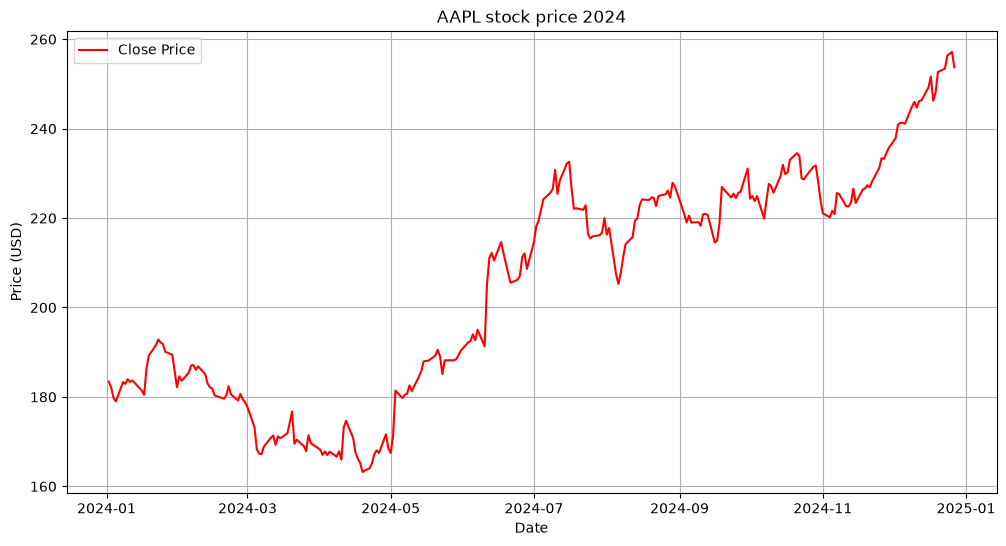

In [44]:
plt.figure(figsize=(12,6))
plt.plot(stock_data.index,stock_data['Close'],label='Close Price',color="red")
plt.title("AAPL stock price 2024")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
stock_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 250 entries, 2024-01-02 to 2024-12-27
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   250 non-null    float64
 1   (High, AAPL)    250 non-null    float64
 2   (Low, AAPL)     250 non-null    float64
 3   (Open, AAPL)    250 non-null    float64
 4   (Volume, AAPL)  250 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.7 KB


# Classical Time Series Decomposition

In [46]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition_additive=seasonal_decompose(stock_data['Close'],model="additive",period=30)

In [47]:
trend_additive=decomposition_additive.trend
seasonal_additive=decomposition_additive.seasonal
residual_additive=decomposition_additive.resid

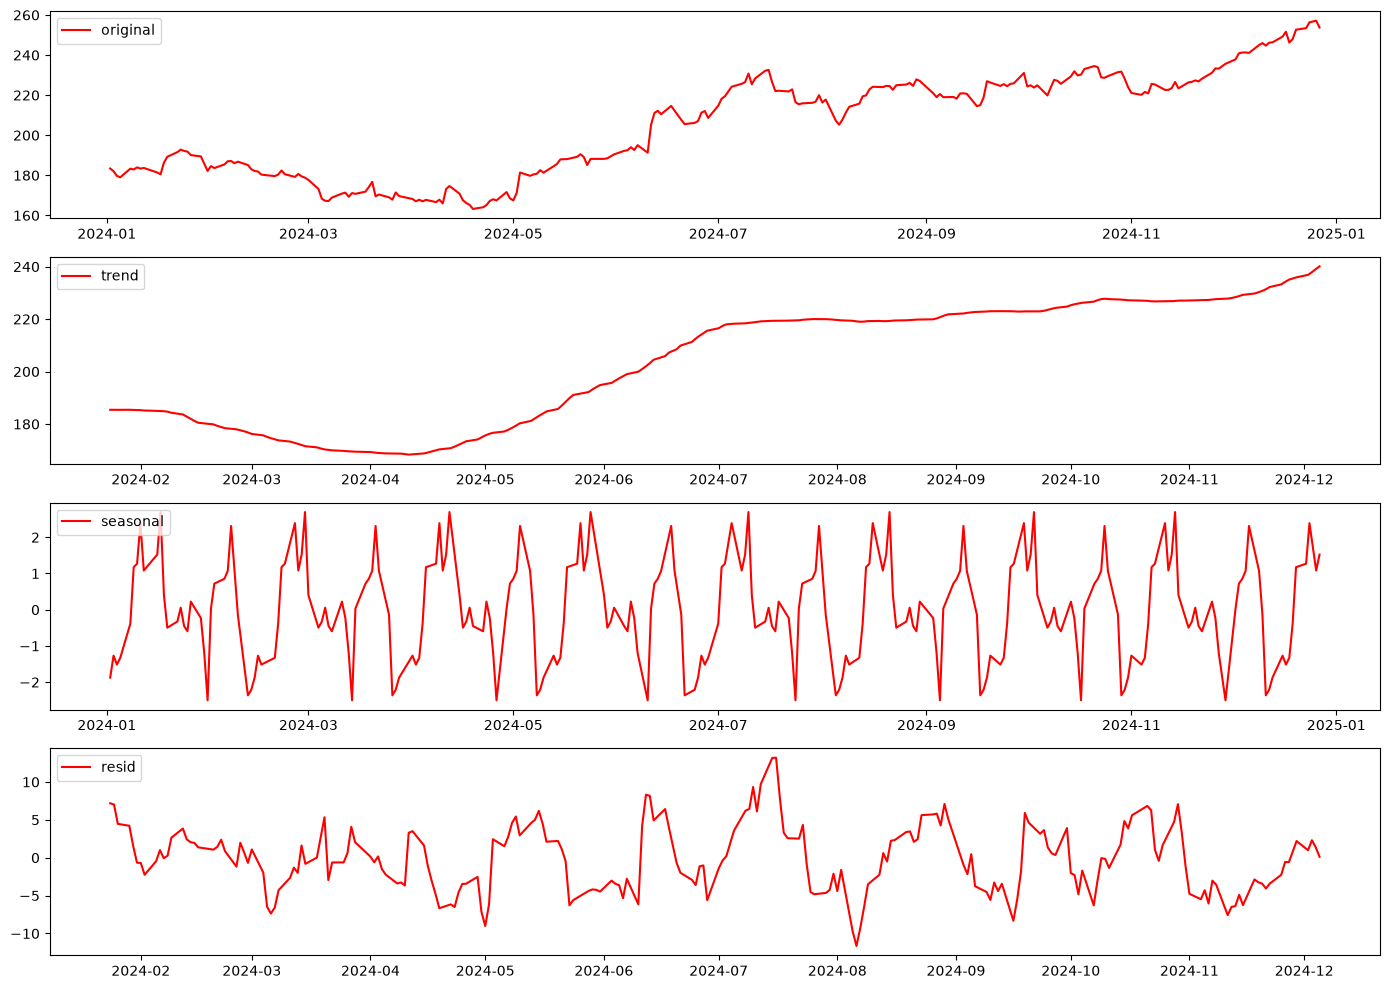

In [48]:
plt.figure(figsize=(14,10))

plt.subplot(4,1,1)
plt.plot(stock_data['Close'],label="original",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,2)
plt.plot(trend_additive,label="trend",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,3)
plt.plot(seasonal_additive,label="seasonal",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,4)
plt.plot(residual_additive,label="resid",color='red')
plt.legend(loc="upper left")

plt.tight_layout()

           


In [49]:


# Make Close a simple Series (yfinance gives AAPL as a 2nd column level)
close = stock_data['Close'].squeeze()

print(close.index.dtype)                     # should say datetime64[ns]
print(close.index.is_monotonic_increasing)   # should be True (dates in order)

datetime64[s]
True


In [50]:
close.index.year          # 2024
close.index.month         # 1 to 12
close.index.day           # day of month
close.index.dayofweek     # 0 = Monday ... 4 = Friday
close.index.day_name()    # 'Monday', 'Tuesday', ...
close.index.quarter       # 1 to 4
close.index.dayofyear     # 1 to 366
close.index.is_month_end  # True/False

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [51]:
parts = pd.DataFrame({
    'close':     close,
    'year':      close.index.year,
    'month':     close.index.month,
    'weekday':   close.index.day_name(),
    'dayofweek': close.index.dayofweek,
    'quarter':   close.index.quarter,
})
parts.head()

,close,year,month,weekday,dayofweek,quarter
Date,,,,,,
2024-01-02,183.404007,2024,1,Tuesday,1,1
2024-01-03,182.030762,2024,1,Wednesday,2,1
2024-01-04,179.718933,2024,1,Thursday,3,1
2024-01-05,178.997726,2024,1,Friday,4,1
2024-01-08,183.324982,2024,1,Monday,0,1


# Stationary Test

In [52]:
from statsmodels.tsa.stattools import adfuller

# Perform the augmeneted Dickery-fuller test
adf_test=adfuller(stock_data['Close'])

print("ADF test Results")
print(f"ADF statistics :{round(adf_test[0],3)}")
print(f'p-value :{round(adf_test[1],3)}')
print("Critical Value:")
for key,value in adf_test[4].items():
    print(f" {key}:{round(value,3)}")




ADF test Results
ADF statistics :-0.039
p-value :0.955
Critical Value:
 1%:-3.457
 5%:-2.873
 10%:-2.573


In [53]:
from statsmodels.tsa.stattools import kpss

# Perform the augmeneted Dickery-fuller test
kpss_test=kpss(stock_data['Close'],regression='ct')             # "c"  for constant lvl stationary "ct" for trend

print("KPSS test Results")
print(f" KPSS statistics :{round(kpss_test[0],3)}")
print(f'p-value :{round(kpss_test[1],3)}')
print("Critical Value:")
for key,value in kpss_test[3].items():
    print(f" {key}:{value}")

KPSS test Results
 KPSS statistics :0.195
p-value :0.018
Critical Value:
 10%:0.119
 5%:0.146
 2.5%:0.176
 1%:0.216


In [58]:
prices=stock_data['Close']

In [59]:
prices

Ticker,AAPL
Date,
2024-01-02,183.404007
2024-01-03,182.030762
2024-01-04,179.718933
2024-01-05,178.997726
2024-01-08,183.324982
...,...
2024-12-20,252.656479
2024-12-23,253.430847
2024-12-24,256.339722


In [62]:
prices.diff()

Ticker,AAPL
Date,
2024-01-02,NaN
2024-01-03,-1.373245
2024-01-04,-2.311829
2024-01-05,-0.721207
2024-01-08,4.327255
...,...
2024-12-20,4.666183
2024-12-23,0.774368
2024-12-24,2.908875


# Synthetic dataset

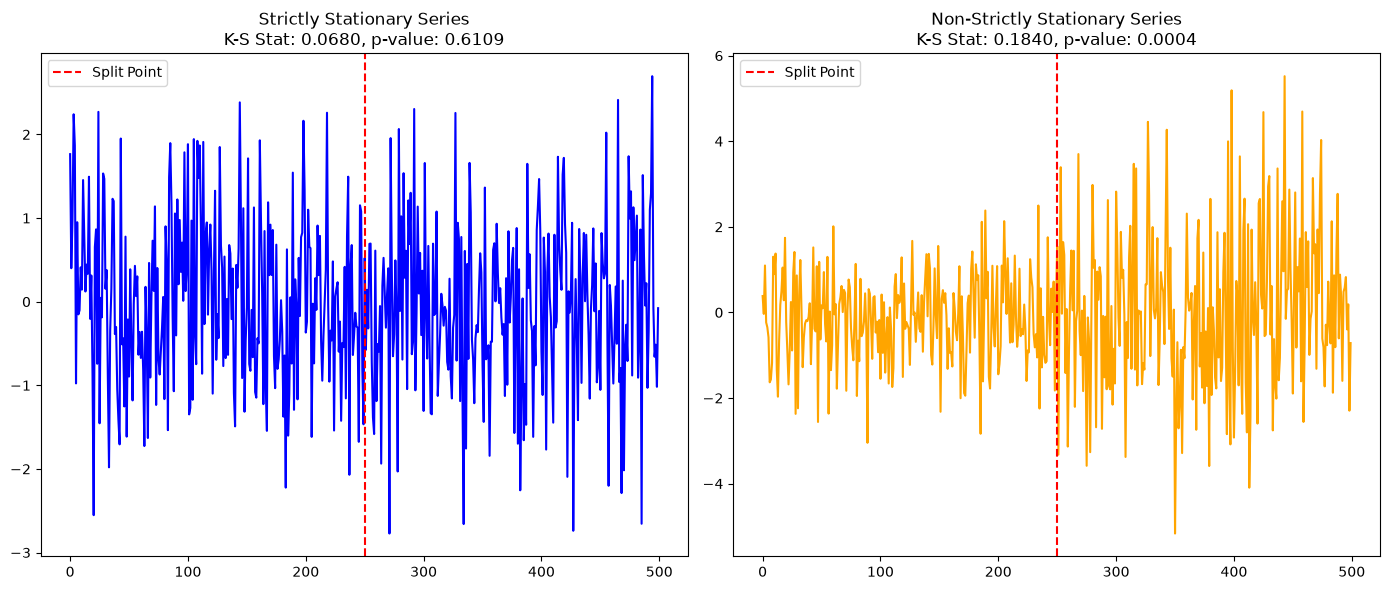

Strictly Stationary Series -> K-S Statistic: 0.0680, p-value: 0.6109
Non-Strictly Stationary Series -> K-S Statistic: 0.1840, p-value: 0.0004


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Generating synthetic data for demonstration
np.random.seed(0)
n = 500

# Strictly stationary series: normally distributed random noise
strict_stationary_series = np.random.normal(0, 1, n)

# Non-strictly stationary series: changing variance
non_strict_stationary_series = np.concatenate([
    np.random.normal(0, 1, n // 2),
    np.random.normal(0, 2, n // 2)
])

# Function to split the series into two halves and perform the K-S test
def ks_test_stationarity(series):
    split = len(series) // 2
    series_first_half = series[:split]
    series_second_half = series[split:]
    stat, p_value = ks_2samp(series_first_half, series_second_half)
    return stat, p_value

# Perform the K-S test on strictly stationary series
ks_stat_strict, ks_pvalue_strict = ks_test_stationarity(strict_stationary_series)

# Perform the K-S test on non-strictly stationary series
ks_stat_non_strict, ks_pvalue_non_strict = ks_test_stationarity(non_strict_stationary_series)

# Plotting the series
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(strict_stationary_series, color='blue')
plt.title(f'Strictly Stationary Series\nK-S Stat: {ks_stat_strict:.4f}, p-value: {ks_pvalue_strict:.4f}')
plt.axvline(x=n // 2, color='red', linestyle='--', label='Split Point')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(non_strict_stationary_series, color='orange')
plt.title(f'Non-Strictly Stationary Series\nK-S Stat: {ks_stat_non_strict:.4f}, p-value: {ks_pvalue_non_strict:.4f}')
plt.axvline(x=n // 2, color='red', linestyle='--', label='Split Point')
plt.legend()

plt.tight_layout()
plt.show()

# Print test results
print(f"Strictly Stationary Series -> K-S Statistic: {ks_stat_strict:.4f}, p-value: {ks_pvalue_strict:.4f}")
print(f"Non-Strictly Stationary Series -> K-S Statistic: {ks_stat_non_strict:.4f}, p-value: {ks_pvalue_non_strict:.4f}")

In [72]:
import numpy as np
from scipy import stats

# Log transformation
prices_log=np.log(prices)

# Square root transformation
prices_sqrt=np.sqrt(prices)

# Box-Cox transformation
prices_boxcox,lam=stats.boxcox(prices[prices>0])

ValueError: Data must be 1-dimensional.

In [68]:
# Extract as 1D Series, keep values > 0, and remove any NaNs
clean_prices = prices.iloc[:, 0]
clean_prices = clean_prices[clean_prices > 0].dropna()

# Box-Cox transformation
prices_boxcox, lam = stats.boxcox(clean_prices)

In [69]:
clean_prices = prices['Close'][prices['Close'] > 0].dropna()

prices_boxcox, lam = stats.boxcox(clean_prices)

KeyError: 'Close'

# Making a time series data Data ,Stationary

In [34]:
# Differencing (the main tool)
# Instead of the price, look at the change from the previous step. Differencing removes a trend
    

In [35]:
diff1=close.diff().dropna() # today minus yesterday
check_stationary(diff1,"First Differnce")

NameError: name 'check_stationary' is not defined

# Transformation
- Log transform
- Log returns

# Log transform and log returns

- When swings get bigger as the level rises (typical for prices), take the log first to calm the variance, then difference.
- The result is the log return, roughly the percentage change.

In [36]:
log_ret = np.log(close).diff().dropna()
check_stationarity(log_ret, "Log return")

NameError: name 'check_stationarity' is not defined

# Detrending -Removing trend component
- Fit a trend line and subtract it. This works for a trend-stationary series (the third row of the table above).

In [37]:
x = np.arange(len(close))
coef = np.polyfit(x, close.values, 1)          # straight-line trend
detrended = close - (coef[0] * x + coef[1])
check_stationarity(detrended, "Detrended (linear)")

NameError: name 'check_stationarity' is not defined